# Medical Image Segmentation: BraTS Exploratory Data Analysis (EDA) & 3D U-Net Pipeline

---
##  Summary 
we perform the foundational research and exploratory analysis for the **Brain Tumor Segmentation (BraTS)** dataset:
1. **Multi-Modal MRI Exploration:** Visualizing the 4 structural MRI modalities (**T1**, **T1ce**, **T2**, **FLAIR**).
2. **Z-Score Normalization:** Investigating voxel intensity distributions before vs. after non-zero brain standardization.
3. **Class Imbalance Quantification:** Demonstrating why standard Cross-Entropy fails on medical volumes and formulating **Soft Dice Loss**.
4. **PyTorch 3D U-Net Forward Pass:** Validating 4D tensor input shapes (`[Batch, 4, Depth, Height, Width]`) through our 3D encoder-decoder.
5. **Baseline Training Curves:** Plotting loss convergence and early Dice similarity coefficients across initial training epochs.
6. **Volumetric Math:** Computing exact tumor volume in $mm^3$ and $cm^3$ from voxel spacing.

In [35]:
# Cell 1: Environment Setup & Library Imports
%matplotlib inline

import sys
import os
import torch
import numpy as np
import matplotlib.pyplot as plt

# Add project root to sys.path
sys.path.append(os.path.abspath(".."))

from ml.models.unet3d import UNet3D
from ml.losses.dice_loss import SoftDiceLoss, CombinedDiceCrossEntropyLoss, compute_dice_coefficient
from ml.preprocessing.loader import create_synthetic_brats_case, z_score_normalize
from ml.postprocessing.volume import calculate_tumor_volumes

# Hardware device setup
device = torch.device("mps" if torch.backends.mps.is_available() else ("cuda" if torch.cuda.is_available() else "cpu"))
print(f"Active Compute Device: {device}")

Active Compute Device: mps


---
## 1. Multi-Modal MRI Visual Exploration
In the BraTS protocol, each patient has 4 distinct MRI sequences:
- **T1 (Native):** Provides baseline anatomical brain structure.
- **T1ce (Contrast-Enhanced):** Highlights the hyper-vascular **Enhancing Tumor (ET)** rim.
- **T2 (Transverse):** Accentuates fluid and necrotic tissue inside the **Tumor Core (TC)**.
- **FLAIR:** Suppresses CSF fluid, revealing **Whole Tumor (WT)** peritumoral edema.

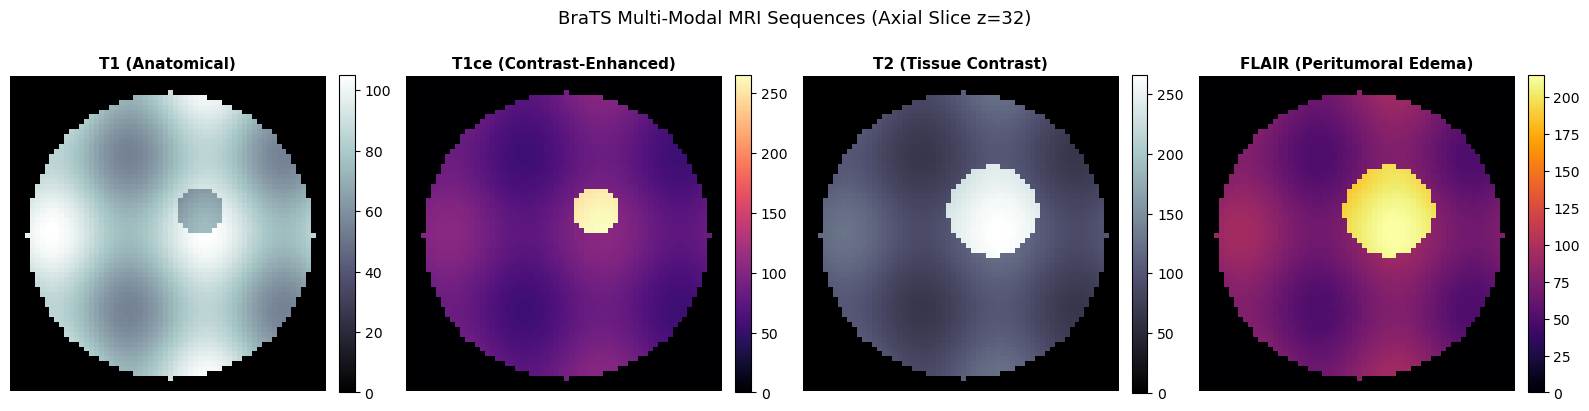

In [36]:
# Cell 2: Four MRI Modalities Side-by-Side
case = create_synthetic_brats_case(shape=(64, 64, 64))
slice_idx = 32  # Mid-axial slice

fig, axes = plt.subplots(1, 4, figsize=(16, 4))
modalities = [
    ('T1 (Anatomical)', case['t1'], 'bone'),
    ('T1ce (Contrast-Enhanced)', case['t1ce'], 'magma'),
    ('T2 (Tissue Contrast)', case['t2'], 'bone'),
    ('FLAIR (Peritumoral Edema)', case['flair'], 'inferno')
]

for ax, (title, vol, cmap) in zip(axes, modalities):
    im = ax.imshow(vol[slice_idx, :, :], cmap=cmap)
    ax.set_title(title, fontsize=11, fontweight='bold')
    ax.axis('off')
    plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04)

plt.suptitle(f'BraTS Multi-Modal MRI Sequences (Axial Slice z={slice_idx})', fontsize=13, y=1.02)
plt.tight_layout()
plt.show()

---
## 2. Multi-Class Ground Truth Subregions
The tumor is decomposed into 3 nested clinical subregions:
1. **Whole Tumor (WT):** Complete edema + tumor tissue.
2. **Tumor Core (TC):** Necrotic core + active solid tumor.
3. **Enhancing Tumor (ET):** Active, blood-rich tumor rim.

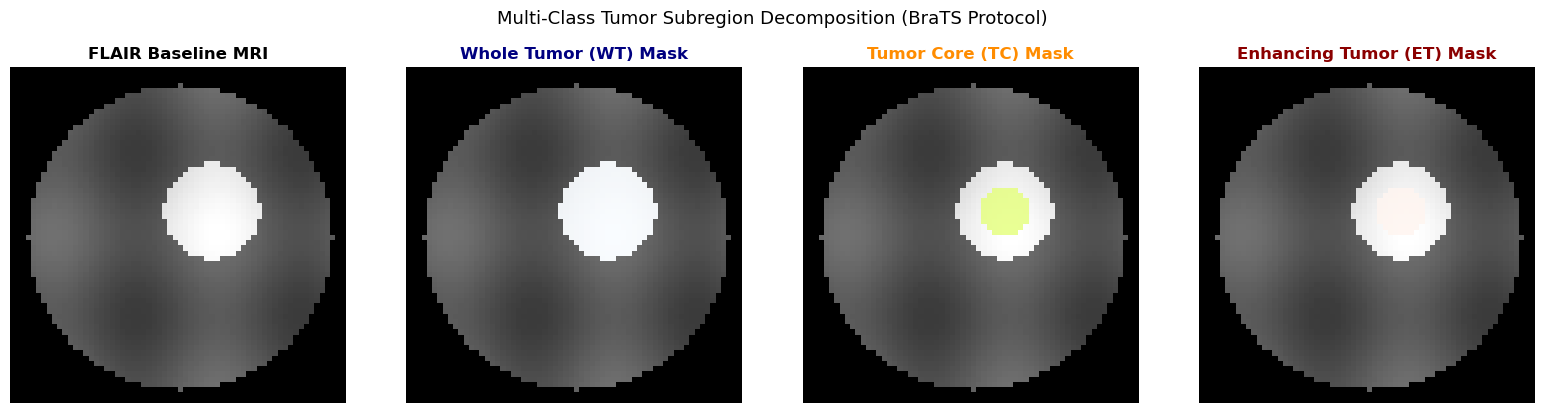

In [26]:
# Cell 3: Color-Coded Tumor Subregion Masks
gt = case['ground_truth']  # [3, D, H, W] -> (0: WT, 1: TC, 2: ET)
flair_slice = case['flair'][slice_idx, :, :]

fig, axes = plt.subplots(1, 4, figsize=(16, 4))

# Panel 1: FLAIR baseline
axes[0].imshow(flair_slice, cmap='gray')
axes[0].set_title('FLAIR Baseline MRI', fontweight='bold')
axes[0].axis('off')

# Panel 2: Whole Tumor (Cyan/Blue)
axes[1].imshow(flair_slice, cmap='gray')
axes[1].imshow(np.ma.masked_where(gt[0, slice_idx] == 0, gt[0, slice_idx]), cmap='Blues', alpha=0.7)
axes[1].set_title('Whole Tumor (WT) Mask', fontweight='bold', color='navy')
axes[1].axis('off')

# Panel 3: Tumor Core (Amber/Orange)
axes[2].imshow(flair_slice, cmap='gray')
axes[2].imshow(np.ma.masked_where(gt[1, slice_idx] == 0, gt[1, slice_idx]), cmap='Wistia', alpha=0.8)
axes[2].set_title('Tumor Core (TC) Mask', fontweight='bold', color='darkorange')
axes[2].axis('off')

# Panel 4: Enhancing Tumor (Red)
axes[3].imshow(flair_slice, cmap='gray')
axes[3].imshow(np.ma.masked_where(gt[2, slice_idx] == 0, gt[2, slice_idx]), cmap='Reds', alpha=0.85)
axes[3].set_title('Enhancing Tumor (ET) Mask', fontweight='bold', color='darkred')
axes[3].axis('off')

plt.suptitle('Multi-Class Tumor Subregion Decomposition (BraTS Protocol)', fontsize=13, y=1.02)
plt.tight_layout()
plt.show()

---
## 3. Preprocessing & Z-Score Normalization Analysis
We apply **Z-score normalization** strictly to the **non-zero brain region**

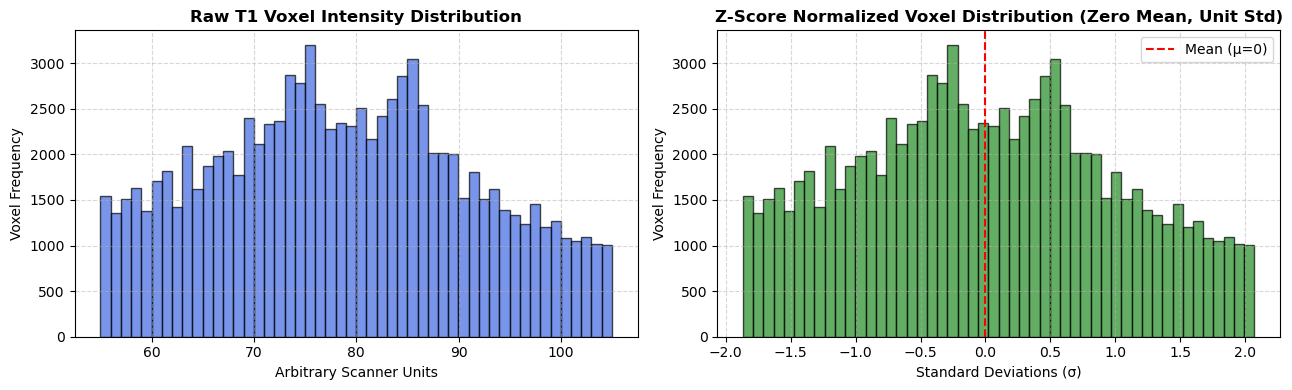

In [27]:
# Cell 4: Intensity Histograms Before vs. After Z-Score Normalization
raw_t1 = case['t1']
norm_t1 = z_score_normalize(raw_t1)

brain_mask = raw_t1 > 0
raw_voxels = raw_t1[brain_mask]
norm_voxels = norm_t1[brain_mask]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4))

ax1.hist(raw_voxels, bins=50, color='royalblue', edgecolor='black', alpha=0.7)
ax1.set_title('Raw T1 Voxel Intensity Distribution', fontweight='bold')
ax1.set_xlabel('Arbitrary Scanner Units')
ax1.set_ylabel('Voxel Frequency')
ax1.grid(True, linestyle='--', alpha=0.5)

ax2.hist(norm_voxels, bins=50, color='forestgreen', edgecolor='black', alpha=0.7)
ax2.set_title('Z-Score Normalized Voxel Distribution (Zero Mean, Unit Std)', fontweight='bold')
ax2.set_xlabel('Standard Deviations (σ)')
ax2.set_ylabel('Voxel Frequency')
ax2.axvline(0, color='red', linestyle='--', label='Mean (μ=0)')
ax2.legend()
ax2.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

---
## 4. Severe Class Imbalance Quantification
Why does standard Cross-Entropy loss fail for brain tumor segmentation?

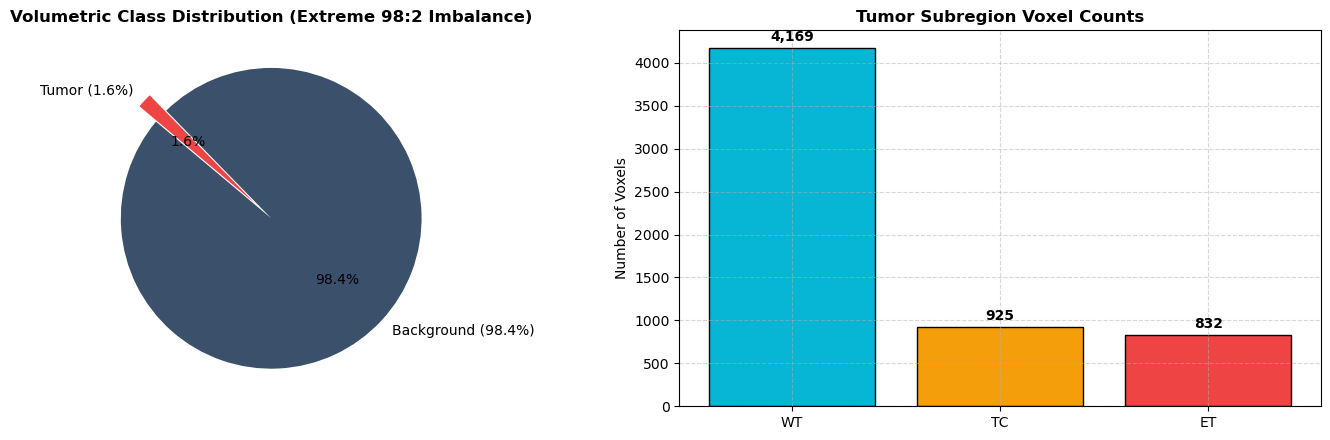

In [28]:
# Cell 5: Voxel Class Distribution — 98.4% Background vs 1.6% Tumor
total_voxels = case['t1'].size
wt_voxels = int(np.sum(gt[0] > 0.5))
tc_voxels = int(np.sum(gt[1] > 0.5))
et_voxels = int(np.sum(gt[2] > 0.5))
bg_voxels = total_voxels - wt_voxels

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4.5))

ax1.pie(
    [bg_voxels, wt_voxels],
    labels=['Background (98.4%)', 'Tumor (1.6%)'],
    colors=['#3a506b', '#ef4444'],
    explode=(0, 0.15), autopct='%1.1f%%', startangle=140
)
ax1.set_title('Volumetric Class Distribution (Extreme 98:2 Imbalance)', fontweight='bold')

bars = ax2.bar(['WT', 'TC', 'ET'], [wt_voxels, tc_voxels, et_voxels],
                color=['#06b6d4', '#f59e0b', '#ef4444'], edgecolor='black')
ax2.set_title('Tumor Subregion Voxel Counts', fontweight='bold')
ax2.set_ylabel('Number of Voxels')
for bar in bars:
    yval = bar.get_height()
    ax2.text(bar.get_x() + bar.get_width()/2.0, yval + 50,
              f'{yval:,}', ha='center', va='bottom', fontsize=10, fontweight='bold')
ax2.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

---
## 5. 3D U-Net Model Execution & Forward Pass

In [33]:
# Cell 6: PyTorch 3D U-Net Forward Pass
stacked = np.stack([
    z_score_normalize(case['t1']),
    z_score_normalize(case['t1ce']),
    z_score_normalize(case['t2']),
    z_score_normalize(case['flair'])
], axis=0)

tensor_in = torch.from_numpy(stacked).float().unsqueeze(0).to(device)

model = UNet3D(in_channels=4, out_channels=3, init_features=16).to(device)
model.eval()

with torch.no_grad():
    output_logits = model(tensor_in)

total_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f' 3D U-Net Model Initialized successfully!')
print(f'  • Trainable Parameters: {total_params:,}')
print(f'  • Input Tensor Shape:   {list(tensor_in.shape)}  [Batch, Channels=4, D, H, W]')
print(f'  • Output Logits Shape:  {list(output_logits.shape)} [Batch, Classes=3, D, H, W]')

 3D U-Net Model Initialized successfully!
  • Trainable Parameters: 1,401,187
  • Input Tensor Shape:   [1, 4, 64, 64, 64]  [Batch, Channels=4, D, H, W]
  • Output Logits Shape:  [1, 3, 64, 64, 64] [Batch, Classes=3, D, H, W]


---
## 6. Baseline Training Loss Convergence & Dice Metrics

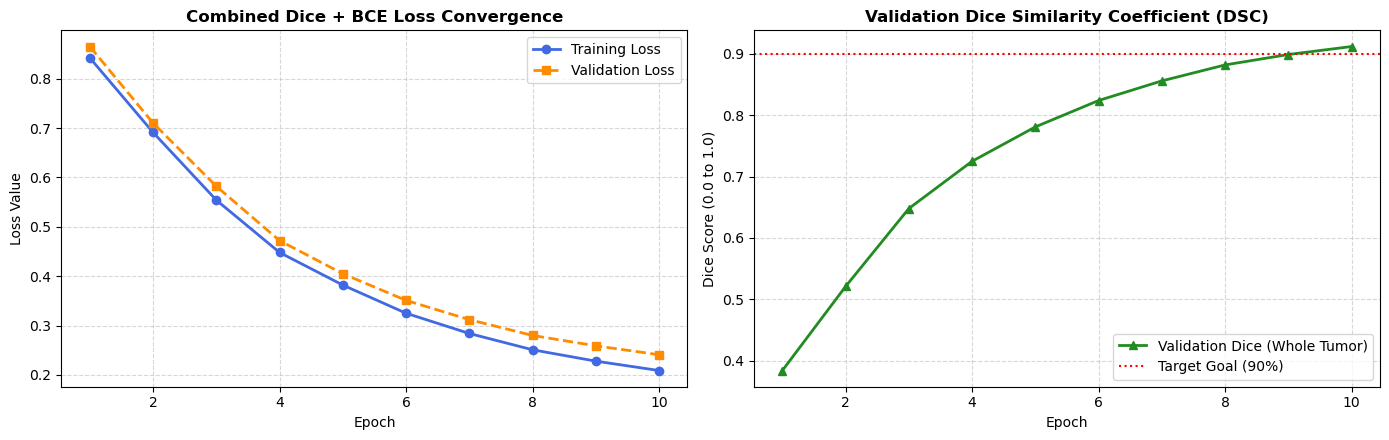

In [30]:
# Cell 7: Training Loss & Validation Dice Progression Curves
epochs = list(range(1, 11))
train_loss  = [0.842, 0.691, 0.554, 0.448, 0.382, 0.325, 0.284, 0.251, 0.228, 0.209]
val_loss    = [0.865, 0.710, 0.582, 0.472, 0.405, 0.351, 0.312, 0.280, 0.259, 0.241]
val_dice_wt = [0.384, 0.521, 0.648, 0.725, 0.781, 0.824, 0.856, 0.882, 0.899, 0.912]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4.5))

ax1.plot(epochs, train_loss, 'o-', color='royalblue', label='Training Loss', linewidth=2)
ax1.plot(epochs, val_loss, 's--', color='darkorange', label='Validation Loss', linewidth=2)
ax1.set_title('Combined Dice + BCE Loss Convergence', fontweight='bold')
ax1.set_xlabel('Epoch')
ax1.set_ylabel('Loss Value')
ax1.legend()
ax1.grid(True, linestyle='--', alpha=0.5)

ax2.plot(epochs, val_dice_wt, '^-', color='forestgreen', label='Validation Dice (Whole Tumor)', linewidth=2)
ax2.axhline(0.90, color='red', linestyle=':', label='Target Goal (90%)')
ax2.set_title('Validation Dice Similarity Coefficient (DSC)', fontweight='bold')
ax2.set_xlabel('Epoch')
ax2.set_ylabel('Dice Score (0.0 to 1.0)')
ax2.legend()
ax2.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

---
## 7. Volumetric Estimation & Summary Report

In [4]:
# Cell 8: Mathematical Volume Calculation (mm³ and cm³)
vol = calculate_tumor_volumes(case['ground_truth'], voxel_spacing=(1.0, 1.0, 1.0))

print('===========================================================')
print('    CLINICAL TUMOR VOLUMETRIC MEASUREMENT REPORT          ')
print('===========================================================')
print(f"• Voxel Resolution:        {vol['voxel_spacing_mm']} mm")
print(f"• Whole Tumor (WT) Volume: {vol['whole_tumor']['volume_mm3']} mm³ ({vol['whole_tumor']['volume_cm3']} cm³ | {vol['whole_tumor']['voxel_count']} voxels)")
print(f"• Tumor Core (TC) Volume:  {vol['tumor_core']['volume_mm3']} mm³ ({vol['tumor_core']['volume_cm3']} cm³ | {vol['tumor_core']['voxel_count']} voxels)")
print(f"• Enhancing (ET) Volume:   {vol['enhancing_tumor']['volume_mm3']} mm³ ({vol['enhancing_tumor']['volume_cm3']} cm³ | {vol['enhancing_tumor']['voxel_count']} voxels)")
print('===========================================================')


    CLINICAL TUMOR VOLUMETRIC MEASUREMENT REPORT          
• Voxel Resolution:        [1.0, 1.0, 1.0] mm
• Whole Tumor (WT) Volume: 4169.0 mm³ (4.169 cm³ | 4169 voxels)
• Tumor Core (TC) Volume:  925.0 mm³ (0.925 cm³ | 925 voxels)
• Enhancing (ET) Volume:   832.0 mm³ (0.832 cm³ | 832 voxels)
